<a href="https://colab.research.google.com/github/Xen-04/Portafolio_Mineria_de-_datos/blob/main/02_06_reglas_de_asociacion/lab_apriori_bakery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio · Reglas de asociación con Apriori — Panadería


**Contexto en una frase:** ventas de una panadería-cafetería (Edimburgo, 2016-2017) donde cada compra de un cliente es una *transacción*.

**Contenido**
1. Carga del dataset (kagglehub + Colab Secrets)
2. Descripción y limpieza
3. Codificación binaria (one-hot)
4. Itemsets frecuentes (soporte mínimo justificado)
5. Reglas de asociación
6. Experimento: tres (o más) configuraciones de umbrales
7. Interpretación de negocio
8. Verificación manual de una regla
9. Reflexión final

## 1 · Carga de datos


In [ ]:
!pip -q install mlxtend kagglehub

In [ ]:
import os, glob, warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.max_columns", 30, "display.width", 160)

KAGGLE_DATASET = "akashdeepkuila/bakery"
CSV_NAME = "Bakery.csv"

def cargar_csv():
    try:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        import kagglehub
        ruta = kagglehub.dataset_download(KAGGLE_DATASET)
        archivos = glob.glob(os.path.join(ruta, "**", "*.csv"), recursive=True)
        print("Descargado en:", ruta, "| CSV:", archivos)
        return archivos[0]
    except Exception as e:
        print("No se pudo descargar:", repr(e))
        if os.path.exists(CSV_NAME):
            return CSV_NAME
        raise

df_raw = pd.read_csv(cargar_csv())
df_raw.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
  0%|          | 0.00/214k [00:00<?, 

Extracting files...
Descargado en: /root/.cache/kagglehub/datasets/akashdeepkuila/bakery/versions/2 | CSV: ['/root/.cache/kagglehub/datasets/akashdeepkuila/bakery/versions/2/Bakery.csv', '/root/.cache/kagglehub/datasets/akashdeepkuila/bakery/versions/2/bakery_sales_revised.csv']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packa

,TransactionNo,Items,DateTime,Daypart,DayType
0,1,Bread,2016-10-30 09:58:11,Morning,Weekend
1,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
2,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
3,3,Hot chocolate,2016-10-30 10:07:57,Morning,Weekend
4,3,Jam,2016-10-30 10:07:57,Morning,Weekend


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2 · Descripción y limpieza

**Definiciones**
- **Transacción:** una compra de un cliente (una boleta), identificada por `TransactionNo`.
- **Ítem:** un producto de la columna `Items` incluido en esa compra.
- Cada fila del archivo = un ítem dentro de una transacción (formato "largo").

In [ ]:
col_tx   = "TransactionNo"
col_item = "Items"

print("Filas:", len(df_raw))
print("Transacciones distintas:", df_raw[col_tx].nunique())
print("Ítems distintos (sin limpiar):", df_raw[col_item].nunique())
print("\nNulos por columna:\n", df_raw.isna().sum())
print("\nÍtems por transacción:\n", df_raw.groupby(col_tx).size().describe().round(2))

Filas: 20507
Transacciones distintas: 9465
Ítems distintos (sin limpiar): 94

Nulos por columna:
 TransactionNo    0
Items            0
DateTime         0
Daypart          0
DayType          0
dtype: int64

Ítems por transacción:
 count    9465.00
mean        2.17
std         1.30
min         1.00
25%         1.00
50%         2.00
75%         3.00
max        11.00
dtype: float64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
df = df_raw.copy()

# 1) Espacios sobrantes / mayúsculas inconsistentes
con_espacios = df[col_item].ne(df[col_item].str.strip()).sum()
print("Filas con espacios sobrantes en el nombre:", con_espacios)
df[col_item] = df[col_item].str.strip()
print("Nombres que solo difieren por mayúsculas:",
      df[col_item].str.lower().nunique() != df[col_item].nunique())

# 2) Filas que no son productos reales (ajustes contables, vales)
no_productos = ["Adjustment", "Gift voucher", "NONE"]
print("Filas no-producto:", df[col_item].isin(no_productos).sum())
df = df[~df[col_item].isin(no_productos)]

# 3) Mismo ítem repetido dentro de la misma boleta (varias unidades)
dup = df.duplicated([col_tx, col_item]).sum()
print("Filas repetidas (misma boleta e ítem):", dup, "-> Apriori mide presencia, no cantidad")
df = df.drop_duplicates([col_tx, col_item])

print("\nTras limpiar -> transacciones:", df[col_tx].nunique(), "| ítems:", df[col_item].nunique())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Filas con espacios sobrantes en el nombre: 21
Nombres que solo difieren por mayúsculas: False
Filas no-producto: 2
Filas repetidas (misma boleta e ítem): 1620 -> Apriori mide presencia, no cantidad

Tras limpiar -> transacciones: 9464 | ítems: 92


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Items
Coffee           4528
Bread            3097
Tea              1350
Cake              983
Pastry            815
Sandwich          680
Medialuna         585
Hot chocolate     552
Cookies           515
Brownie           379
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

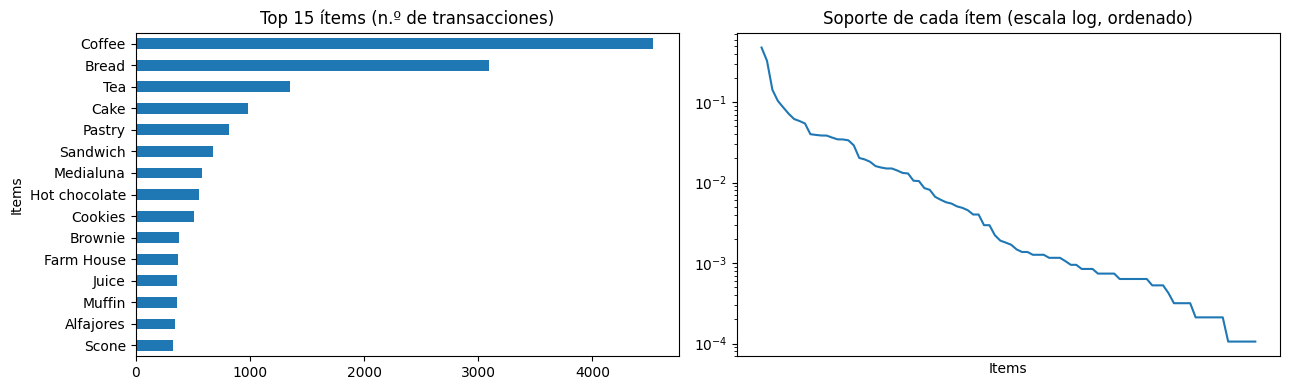

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
frec = df[col_item].value_counts()
print(frec.head(10))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
frec.head(15).sort_values().plot.barh(ax=ax[0], title="Top 15 ítems (n.º de transacciones)")
(frec / df[col_tx].nunique()).plot(ax=ax[1], logy=True, title="Soporte de cada ítem (escala log, ordenado)")
ax[1].set_xticks([]); plt.tight_layout(); plt.show()

## 3 · Codificación binaria (one-hot)

Apriori no lee listas de productos, cuenta **en cuántas transacciones aparece cada combinación**. Para eso necesita una matriz con **una fila por transacción y una columna por ítem**, con `True` si el ítem está en la compra y `False` si no. Así, contar el soporte de un ítem o de un par es sumar/combinar columnas booleanas, algo muy rápido. Además, por definición, ignora cantidades y orden.

In [ ]:
basket = (df.assign(v=True)
            .pivot_table(index=col_tx, columns=col_item, values="v", fill_value=False, aggfunc="max")
            .astype(bool))
N = len(basket)
print("Tabla codificada:", basket.shape, "(transacciones x ítems)")
basket.iloc[:8, :8]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Tabla codificada: (9464, 92) (transacciones x ítems)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Items,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn
TransactionNo,,,,,,,,
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4 · Itemsets frecuentes — elección del soporte mínimo

Soporte = proporción de transacciones que contienen el itemset.

In [ ]:
sop = basket.mean().sort_values(ascending=False)
for u in [0.10, 0.05, 0.02, 0.01, 0.005, 0.002]:
    print(f"soporte >= {u:<6} -> {(sop >= u).sum():>3} ítems  ({u*N:.0f} transacciones mínimo)")

soporte >= 0.1    ->   4 ítems  (946 transacciones mínimo)
soporte >= 0.05   ->   9 ítems  (473 transacciones mínimo)
soporte >= 0.02   ->  19 ítems  (189 transacciones mínimo)
soporte >= 0.01   ->  30 ítems  (95 transacciones mínimo)
soporte >= 0.005  ->  37 ítems  (47 transacciones mínimo)
soporte >= 0.002  ->  44 ítems  (19 transacciones mínimo)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Justificación.** La distribución es muy desigual: pocos ítems (café, pan) concentran casi todas las ventas y hay una cola larga de productos casi únicos (varios con 1-2 ventas, cuyo soporte es ruido). Con 5 % solo quedan 9 ítems y casi no hay reglas; con 0,2 % entran productos con menos de 20 ventas, cuyas reglas son poco fiables. Parto con **1 %** (≈95 transacciones) como base: conserva 30 ítems y cada regla se apoya en un número razonable de compras. Después lo bajo gradualmente (ver sección 6).

In [ ]:
MIN_SUP = 0.01
fi = apriori(basket, min_support=MIN_SUP, use_colnames=True, max_len=3)
fi["k"] = fi["itemsets"].apply(len)
fi["itemsets_txt"] = fi["itemsets"].apply(lambda s: " + ".join(sorted(s)))
print("Itemsets frecuentes:", len(fi), "\n", fi["k"].value_counts().sort_index().to_string())
fi.sort_values("support", ascending=False)[["itemsets_txt", "support", "k"]].head(15)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Itemsets frecuentes: 61 
 k
1    30
2    28
3     3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,itemsets_txt,support,k
6,Coffee,0.478445,1
2,Bread,0.327240,1
26,Tea,0.142646,1
4,Cake,0.103867,1
34,Bread + Coffee,0.090025,2
19,Pastry,0.086116,1
21,Sandwich,0.071851,1
16,Medialuna,0.061813,1
12,Hot chocolate,0.058326,1
42,Cake + Coffee,0.054734,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5 · Reglas de asociación

- **Soporte:** % de compras que contienen antecedente y consecuente.
- **Confianza:** de las compras con el antecedente, % que también llevan el consecuente.
- **Lift:** confianza ÷ soporte del consecuente. >1: se compran juntos más de lo esperado; ≈1: independientes; <1: se evitan.

Ordeno por **lift** (para no quedarme con reglas que solo reflejan que el café es popular), y exijo confianza ≥ 0,30.

In [ ]:
def get_rules(fi, min_conf, n):
    try:
        r = association_rules(fi, num_itemsets=n, metric="confidence", min_threshold=min_conf)
    except TypeError:                       # versiones antiguas de mlxtend
        r = association_rules(fi, metric="confidence", min_threshold=min_conf)
    r["regla"] = r["antecedents"].apply(lambda s: " + ".join(sorted(s))) + "  →  " + \
                 r["consequents"].apply(lambda s: " + ".join(sorted(s)))
    return r

rules = get_rules(fi, 0.30, N)
cols = ["regla", "support", "confidence", "lift"]
rules_sorted = rules.sort_values("lift", ascending=False)
print("Reglas:", len(rules))
rules_sorted[cols].round(3).reset_index(drop=True)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Reglas: 19


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,regla,support,confidence,lift
0,Toast → Coffee,0.024,0.704,1.472
1,Spanish Brunch → Coffee,0.011,0.599,1.252
2,Medialuna → Coffee,0.035,0.569,1.190
3,Pastry → Coffee,0.048,0.552,1.154
4,Alfajores → Coffee,0.020,0.541,1.130
5,Juice → Coffee,0.021,0.534,1.117
6,Sandwich → Coffee,0.038,0.532,1.113
7,Cake → Coffee,0.055,0.527,1.101
8,Scone → Coffee,0.018,0.523,1.093
9,Cookies → Coffee,0.028,0.518,1.084


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

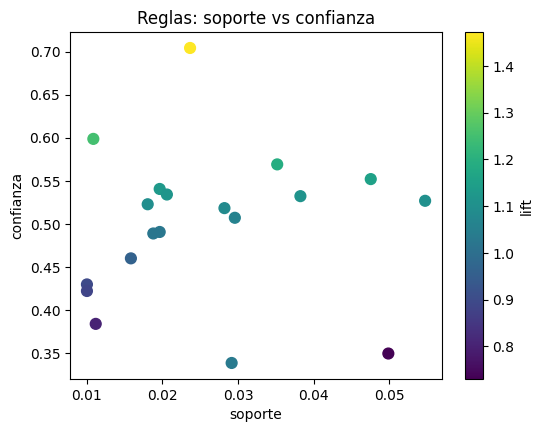

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
plt.figure(figsize=(6, 4.5))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=60)
plt.colorbar(sc, label="lift"); plt.xlabel("soporte"); plt.ylabel("confianza")
plt.title("Reglas: soporte vs confianza"); plt.show()

## 6 · Experimento: comparación de configuraciones

Empieza con umbrales altos y se bajo gradualmente, para no agotar la memoria (`max_len=3` limita el tamaño de los itemsets).

In [ ]:
import time
configs = [("A · muy estricta", 0.05, 0.30),
           ("B · estricta",     0.02, 0.40),
           ("C · base",         0.01, 0.30),
           ("D · base, conf. alta", 0.01, 0.50),
           ("E · laxa",         0.005, 0.30)]
res, store = [], {}
for nombre, s, c in configs:
    t = time.time()
    f = apriori(basket, min_support=s, use_colnames=True, max_len=3)
    r = get_rules(f, c, N) if len(f) > 1 else pd.DataFrame()
    store[nombre] = (f, r)
    res.append({"configuración": nombre, "soporte mín.": s, "confianza mín.": c,
                "itemsets": len(f), "reglas": len(r),
                "reglas con lift>1.2": int((r["lift"] > 1.2).sum()) if len(r) else 0,
                "seg": round(time.time() - t, 2)})
comparativa = pd.DataFrame(res)
comparativa

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,configuración,soporte mín.,confianza mín.,itemsets,reglas,reglas con lift>1.2,seg
0,A · muy estricta,0.050,0.3,11,1,0,0.02
1,B · estricta,0.020,0.4,33,8,1,0.03
2,C · base,0.010,0.3,61,19,2,0.05
3,"D · base, conf. alta",0.010,0.5,61,11,2,0.03
4,E · laxa,0.005,0.3,114,35,5,0.06


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Conclusión.** Bajar el soporte de 5 % a 0,5 % multiplica los itemsets (≈11 - ≈110) y las reglas (1 - ≈35), pero lo nuevo son sobre todo productos de baja venta. Subir la confianza (C - D) recorta reglas sin cambiar los itemsets: filtra relaciones débiles. Con **5 %** casi no hay nada que accionar; con **0,5 %** aparecen reglas llamativas pero con muy pocas compras detrás (p. ej. 51 transacciones). **C (1 % / 0,30)** es el mejor equilibrio entre cantidad de reglas y respaldo; uso C como base y la E como apoyo para explorar nichos.

## 7 · Interpretación de negocio

In [ ]:
f_E, r_E = store["E · laxa"]
top = r_E.sort_values("lift", ascending=False)
top[["regla", "support", "confidence", "lift"]].round(3).head(15).reset_index(drop=True)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,regla,support,confidence,lift
0,Keeping It Local → Coffee,0.005,0.810,1.692
1,Toast → Coffee,0.024,0.704,1.472
2,Salad → Coffee,0.007,0.626,1.309
3,Cake + Hot chocolate → Coffee,0.007,0.602,1.258
4,Spanish Brunch → Coffee,0.011,0.599,1.252
5,Medialuna → Coffee,0.035,0.569,1.190
6,Pastry → Coffee,0.048,0.552,1.154
7,Tiffin → Coffee,0.008,0.548,1.145
8,Alfajores → Coffee,0.020,0.541,1.130
9,Hearty & Seasonal → Coffee,0.006,0.540,1.129


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Las 5 reglas más valiosas

(Valores de la configuración E; los de la C son los mismos para las reglas que comparten.)

1. **Tostadas - Café** (soporte 2,4 %, confianza 70 %, lift 1,47): siete de cada diez clientes que piden tostadas también piden café, mucho más que el cliente promedio; es la combinación de desayuno más sólida y con volumen.
2. **Spanish Brunch - Café** (soporte 1,1 %, confianza 60 %, lift 1,25): el brunch casi siempre viene acompañado de café, así que conviene ofrecerlo dentro del plato del día.
3. **Pastel + Chocolate caliente - Café** (soporte 0,7 %, confianza 60 %, lift 1,26): quien pide una merienda dulce con chocolate suele sumar un café (probablemente para otra persona de la mesa): señal para promover "combo para compartir".
4. **Medialuna - Café** (soporte 3,5 %, confianza 57 %, lift 1,19): relación más débil, pero con mucho volumen; es de las que más compras mueve en términos absolutos.
5. **Ensalada - Café** (soporte 0,7 %, confianza 63 %, lift 1,31): quienes almuerzan ligero suelen cerrar con café; oportunidad en el horario de mediodía.

Mención aparte: **Keeping It Local - Café** tiene el lift más alto (1,69) pero solo ≈51 compras de respaldo; la trato como hipótesis, no como regla de decisión.

### Regla que descartaría: **Té - Café**
Con soporte 5 % y confianza 35 % **supera** los umbrales de la config. C, pero su **lift es 0,73 (< 1)**: los clientes que piden té compran café *menos* que el promedio (≈48 %). Es una sustitución (o una bebida u otra), no una complementariedad. Promover café a quien pide té sería contraproducente. Igualmente descartaría **Pastry - Pan** (confianza 34 %, lift ≈ 1,03): es la popularidad del pan, no una relación real.

### Decisión concreta para el administrador
Crear un **combo "Desayuno": tostadas + café** (y variante brunch + café) con pequeño descuento en el paquete, y poner el mostrador de café junto a tostadas/medialunas para facilitar la venta cruzada. Para clientes de té, **no** empujar café; ofrecer en cambio pasteles o scones. Medir ticket promedio antes y después.

> **extra**: las reglas describen **co-ocurrencias**, no causas ni predicciones; por eso no se calcula accuracy. Y como el café está en ~48 % de las compras, casi todos los lifts son moderados.

## 8 · Verificación manual de una regla (Tostadas → Café)

In [ ]:
# Conteo "a mano" con conjuntos de Python, sin usar mlxtend
cestas = df.groupby(col_tx)[col_item].apply(set)

def contar(cestas):
    n = len(cestas)
    a  = sum("Toast" in c for c in cestas)
    ab = sum({"Toast", "Coffee"} <= c for c in cestas)
    b  = sum("Coffee" in c for c in cestas)
    return n, a, ab, b

# Muestra
muestra = cestas.iloc[:500]
n, a, ab, b = contar(muestra)
print(f"MUESTRA ({n} transacciones): Toast={a}, Toast&Coffee={ab}, Coffee={b}")
if a: print(f"  soporte={ab/n:.3f}  confianza={ab/a:.3f}  lift={(ab/a)/(b/n):.3f}")

# 2) Datos completos y comparación con mlxtend
n, a, ab, b = contar(cestas)
print(f"\nTODO ({n}): Toast={a}, Toast&Coffee={ab}, Coffee={b}")
print(f"  soporte={ab/n:.4f}  confianza={ab/a:.4f}  lift={(ab/a)/(b/n):.4f}")
print("\nmlxtend:")
r_E[r_E["regla"] == "Toast  →  Coffee"][["support", "confidence", "lift"]].round(4)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

MUESTRA (500 transacciones): Toast=0, Toast&Coffee=0, Coffee=219

TODO (9464): Toast=318, Toast&Coffee=224, Coffee=4528
  soporte=0.0237  confianza=0.7044  lift=1.4723

mlxtend:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,confidence,lift
24,0.0237,0.7044,1.4723


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Si el conteo manual coincide con la fila de mlxtend (soporte ≈ 0,0237; confianza ≈ 0,704; lift ≈ 1,47), la regla está verificada: de las ≈318 compras con tostadas, ≈224 incluyen café.

## 9 · Reflexión final

1. El soporte mínimo es la decisión más sensible: muy alto no deja reglas, muy bajo llena la lista de rarezas.
2. En esta panadería el café domina, así que casi todas las reglas apuntan a él y con lift moderado.
3. Confianza alta no basta: hay que mirar el lift (el caso Té - Café lo muestra).
4. Las reglas con pocas transacciones detrás (≈50) son hipótesis a probar, no verdades.
5. Lo útil para el negocio son combos y ubicación de productos, validados luego con una prueba real.